In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import os



# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# functions to calculate statistics
def RMSE(actual, predicted):
    
    # Convert inputs to numpy arrays 
    actual = np.array(actual)
    predicted = np.array(predicted)

    
    # Calculate the squared differences
    squared_diff = (actual - predicted) ** 2
    
    # Compute the mean of squared differences
    mean_squared_diff = np.mean(squared_diff)
    
    # Take the square root of the mean squared difference
    return np.sqrt(mean_squared_diff)

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]


proteins = ['alpha3D']

Posterior 1: phi = 0.9176, chi2 = 7.4048
Posterior 2: phi = 0.3133, chi2 = 0.3682


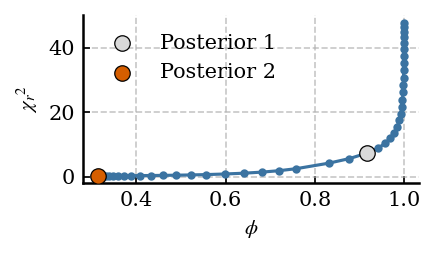

In [8]:
# chi2 vs phi from the NMR ensemble

protein = proteins[0]

# reweighting data NMR
wopt_array = np.load(f'../../MD_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(f'../../MD_DATA/{protein}/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]
chi2 = rewdata[0,:]

# posterior 1 = elbow
wopt1 = np.load(f'../../MD_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
# posterior 2 = final with phi > 0.1
wopt2 = np.load(f'../../MD_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# identify the three posterior points
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1: phi = {phi[idx_post1]:.4f}, chi2 = {chi2[idx_post1]:.4f}")
print(f"Posterior 2: phi = {phi[idx_post2]:.4f}, chi2 = {chi2[idx_post2]:.4f}")

# colours
COLOR_CURVE = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST2 = "#D55E00"

# sort by phi for a clean line
order = np.argsort(phi)

fig, ax = plt.subplots(figsize=(3, 1.8))

ax.plot(phi[order], chi2[order], "-o", color=COLOR_CURVE, markersize=3, linewidth=1.5, zorder=2)

# highlight selected posteriors
ax.scatter(phi[idx_post1], chi2[idx_post1], s=55, color=COLOR_POST1, edgecolor="black", linewidth=0.6, label="Posterior 1", zorder=4)
ax.scatter(phi[idx_post2], chi2[idx_post2], s=55, color=COLOR_POST2, edgecolor="black", linewidth=0.6, label="Posterior 2", zorder=4)

ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\chi$$_{r}$$^{2}$")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig(f"chi2_vs_phi_NMR_{protein}.pdf") 
plt.show()

Posterior 1 phi = 0.9176
Posterior 2 phi = 0.3133


/tmp/ipykernel_2521389/2931358301.py:35: RuntimeWarning: divide by zero encountered in divide
  PFprior = 1 / np.mean(fopen, axis=0)
/tmp/ipykernel_2521389/2931358301.py:36: RuntimeWarning: divide by zero encountered in divide
  PF1 = 1 / np.average(fopen, weights=wopt1, axis=0)
/tmp/ipykernel_2521389/2931358301.py:37: RuntimeWarning: divide by zero encountered in divide
  PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)


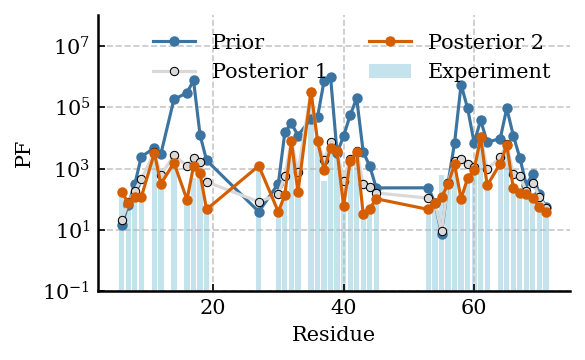

In [10]:
# comparison of NMR protection factors and prior/posterior

protein = proteins[0]

exp = pd.read_csv(f'../../EXP_DATA/PF_Nguyen_2018/{protein}.csv')

# get fopen
fopen = np.load(f'../../MD_DATA/{protein}/rewM14DH_scaled/O.npy')
res = np.loadtxt(f'../../MD_DATA/{protein}/rewM14DH_scaled/amideresidues.txt').astype(int)
exp_residues = np.loadtxt(f'../../MD_DATA/{protein}/rewM14DH_scaled/exp_residues.txt').astype(int)

# indices corresponding to the same common residue set
exp_idxs_comp = np.array([list(res).index(ele) for ele in exp_residues])
exp_idxs_exp = np.array([list(exp['Model_residue']).index(ele) for ele in exp_residues])

# reweighting data
wopt_array = np.load(f'../../MD_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(f'../../MD_DATA/{protein}/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

# posterior 1 = elbow
wopt1 = np.load(f'../../MD_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# posterior 2 = final
wopt2 = np.load(f'../../MD_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# identify phi values
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1 phi = {phi[idx_post1]:.4f}")
print(f"Posterior 2 phi = {phi[idx_post2]:.4f}")

# PFs for all computed amide residues
PFprior = 1 / np.mean(fopen, axis=0)
PF1 = 1 / np.average(fopen, weights=wopt1, axis=0)
PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)

# select the common experimental residues in exactly the same order
plot_res = exp_residues
PFexp = exp['PF'].to_numpy()[exp_idxs_exp]
PFprior_plot = PFprior[exp_idxs_comp]
PF1_plot = PF1[exp_idxs_comp]
PF2_plot = PF2[exp_idxs_comp]

# colours
COLOR_PRIOR = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST2 = "#D55E00"
COLOR_EXP = "lightblue"

# plot
fig, ax = plt.subplots(figsize=(4,2.5))

ax.bar(plot_res, PFexp, width=0.8, color=COLOR_EXP, edgecolor="none", alpha=0.7, label="Experiment", zorder=1)
ax.plot(plot_res, PFprior_plot, "-o", color=COLOR_PRIOR, markersize=4, linewidth=1.5, label="Prior", zorder=3)
ax.plot(plot_res, PF1_plot, "-o", color=COLOR_POST1, markeredgecolor="black", markeredgewidth=0.5, markersize=4, linewidth=1.5, label=rf"Posterior 1", zorder=4)
ax.plot(plot_res, PF2_plot, "-o", color=COLOR_POST2, markersize=4, linewidth=1.5, label=rf"Posterior 2", zorder=5)

ax.set_yscale("log")
ax.set_xlabel("Residue")
ax.set_ylabel("PF")
ax.set_ylim(1e-1, 1e8)
ax.legend(frameon=False, ncol=2)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig(f'EXP_vs_CALC_PF_NMR_{protein}.pdf')
plt.show()